# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Revalina Natasya Sinaga
- **Email:** ds284b6x1542@student.devacademy.id
- **ID Dicoding:** DS284B6X1542

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada periode 2011–2012, bagaimana rata-rata jumlah penyewaan sepeda berdasarkan jam dalam sehari, dan jam berapa penyewaan mencapai titik tertinggi dan terendah sebagai dasar penentuan waktu prioritas ketersediaan sepeda?
- **Pertanyaan 2:** Pada periode 2011–2012, bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kategori kondisi cuaca, dan kategori cuaca apa yang memiliki rata-rata penyewaan tertinggi dan terendah sebagai dasar penyesuaian operasional layanan?


## Import Semua Packages/Library yang Digunakan

Pada tahap ini dilakukan import library Python yang digunakan selama proses analisis data. Library Pandas digunakan untuk pengolahan dan manipulasi data, NumPy untuk operasi numerik, Matplotlib dan Seaborn untuk membuat visualisasi data.

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

### Memuat Dataset

Dataset yang digunakan adalah Bike Sharing Dataset. Dataset ini berisi informasi penyewaan sepeda berdasarkan waktu, musim, kondisi cuaca, dan karakteristik lingkungan.

Pada tahap ini digunakan file `hour.csv` yang mencatat aktivitas penyewaan sepeda setiap jam. Data dimuat menggunakan library Pandas ke dalam DataFrame agar dapat diperiksa dan dianalisis lebih lanjut.

In [40]:
df = pd.read_csv('hour.csv')
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Berdasarkan hasil pemuatan dataset, terlihat bahwa data mencatta aktivitas penyewaan sepeda setiap jam. Dataset memiliki 17 kolom yang mencakup informasi tanggal, musim, tahun, bulan, jam, hari kerja, kondiis cuaca, suhu, kelembapan, kecepatan angin serta jumlah penyewaan speda.
- Kolom `cnt` menunjukkan total penyewaan sepeda, sedangkan kolom `casual` dan `registered` menunjukkan jumlah penyewaan dari pengguna kasual dan terdaftar. Data yang ditampilkan pada lima baris pertama menunjukkan bahwa jumlah penyewaan berbeda pada setiap jam.

### Assessing Data

#### Mengidentifikasi Masalah Kualitas Data

Berdasarkan hasil pemeriksaan dataset, terdapat beberapa aspek kualitas data yang perlu diperhatikan sebelum analisis dilakukan:

- Kolom dteday perlu dipastikan menggunakan tipe data datetime agar dapat digunakan dalam analisis berbasis tanggal dan waktu.
- Kolom season, yr, mnth, hr, holiday, weekday, workingday, dan weathersit menggunakan nilai numerik untuk merepresentasikan kategori atau periode tertentu. Oleh karena itu, validitas nilainya perlu diperiksa.
- Rentang nilai pada kolom normalisasi (temp, atemp, hum, dan windspeed) perlu diperiksa untuk memastikan nilainya berada pada rentang 0–1.
- Konsistensi jumlah penyewaan total (cnt) perlu diperiksa dengan membandingkannya terhadap penjumlahan casual dan registered.

Hasil pemeriksaan juga menunjukkan bahwa tidak terdapat missing values maupun data duplikat.

In [41]:
df.info()

print("Jumlah data:", df.shape)

print("\nJumlah missing values:")
print(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

df.describe()

# Memeriksa nilai yang tidak sesuai dengan rentang kategori
rentang_kategori = {
    'season': [1, 2, 3, 4],
    'yr': [0, 1],
    'mnth': list(range(1, 13)),
    'hr': list(range(24)),
    'holiday': [0, 1],
    'weekday': list(range(7)),
    'workingday': [0, 1],
    'weathersit': [1, 2, 3, 4]
}

print("\nPemeriksaan nilai kategori:")

for kolom, nilai_valid in rentang_kategori.items():
    jumlah_invalid = (~df[kolom].isin(nilai_valid)).sum()
    print(f"{kolom}: {jumlah_invalid} nilai tidak valid")


# Memeriksa nilai di luar rentang normalisasi
kolom_normalisasi = ['temp', 'atemp', 'hum', 'windspeed']

print("\nPemeriksaan nilai normalisasi:")

for kolom in kolom_normalisasi:
    jumlah_invalid = (~df[kolom].between(0, 1)).sum()
    print(f"{kolom}: {jumlah_invalid} nilai di luar rentang 0–1")


# Memeriksa konsistensi jumlah penyewaan
jumlah_tidak_sesuai = (
    df['cnt'] != df['casual'] + df['registered']
).sum()

print(
    "\nJumlah data dengan cnt tidak sesuai "
    "dengan casual + registered:",
    jumlah_tidak_sesuai
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB
Jumlah data: (17379, 17)

Jumlah missing values:


### Hasil Pemeriksaan Data

Berdasarkan pemeriksaan awal terhadap dataset Bike Sharing, diperoleh sebanyak **17.379 baris dan 17 kolom**. Hasil pemeriksaan menunjukkan bahwa:

1. Tidak terdapat missing values pada seluruh kolom.
2. Tidak ditemukan data duplikat.
3. Seluruh nilai pada kolom kategori berada dalam rentang nilai yang valid.
4. Seluruh nilai pada kolom normalisasi (`temp`, `atemp`, `hum`, dan `windspeed`) berada dalam rentang 0–1.
5. Tidak ditemukan ketidaksesuaian antara jumlah penyewaan total (`cnt`) dengan penjumlahan penyewaan pengguna kasual (`casual`) dan terdaftar (`registered`).

Dengan demikian, berdasarkan pemeriksaan tersebut, dataset tidak menunjukkan masalah kelengkapan, duplikasi, maupun ketidaksesuaian nilai pada kolom yang diperiksa sehingga dapat dilanjutkan ke tahap analisis data.

**Steps to Take:**
- Mengubah tipe data kolom dteday dari object menjadi datetime agar dapat digunakan dalam analisis berbasis waktu.
- Memeriksa validitas nilai pada kolom-kolom kategori.
- Memeriksa rentang nilai pada kolom normalisasi (temp, atemp, hum, dan windspeed).
- Memeriksa konsistensi jumlah penyewaan total (cnt) dengan penjumlahan casual dan registered.
- Mempertahankan seluruh data karena tidak ditemukan missing values maupun data duplikat.

**Insight:** (Opsional)
- Hasil pemeriksaan menunjukkan bahwa dataset tidak memiliki missing values maupun data duplikat. Seluruh nilai pada kolom kategori berada dalam rentang yang valid, sedangkan nilai pada kolom normalisasi berada dalam rentang 0–1. Selain itu, jumlah penyewaan total (cnt) telah sesuai dengan penjumlahan penyewaan pengguna kasual (casual) dan terdaftar (registered). Dengan demikian, berdasarkan aspek-aspek yang telah diperiksa, dataset tidak memerlukan penanganan lebih lanjut dan dapat dilanjutkan ke tahap berikutnya.

### Cleaning Data

#### Memperbaiki Masalah Kualitas Data

Pada tahap ini dilakukan penyesuaian tipe data pada kolom `dteday` dari object menjadi datetime. Penyesuaian dilakukan agar kolom tanggal dapat dikenali sebagai data bertipe waktu dan mendukung proses analisis lebih lanjut.

In [42]:
df['dteday'] = pd.to_datetime(df['dteday'])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

**Insight:** (Opsional)
- Setelah proses cleaning dilakukan, kolom dteday berhasil diubah menjadi tipe data datetime64[ns]. Perubahan ini memungkinkan informasi tanggal digunakan dalam analisis berbasis waktu. Jumlah data tetap sebanyak 17.379 baris karena tidak ditemukan missing values maupun data duplikat yang perlu ditangani. Dengan demikian, dataset siap digunakan untuk tahap Exploratory Data Analysis (EDA).

## Exploratory Data Analysis (EDA)

### Exploratory Data Analysis (EDA)

Pada tahap ini dilakukan eksplorasi data untuk memahami pola penyewaan sepeda berdasarkan jam dan kondisi cuaca. Eksplorasi dilakukan dengan mengelompokkan data berdasarkan variabel yang berkaitan dengan pertanyaan bisnis, kemudian menghitung rata-rata jumlah penyewaan sepeda menggunakan kolom `cnt`.

In [43]:
#eksplorasi rata-rata jumlah penyewaan brdasarkan jam
rata_jam = df.groupby('hr')['cnt'].mean().reset_index()

rata_jam

,hr,cnt
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


In [44]:
#eksplorasi rata-rata jumlah penyewaan brdasarkan kondisi cuaca
rata_cuaca = (
    df.groupby('weathersit')['cnt']
    .mean()
    .reset_index()
)

rata_cuaca.columns = ['Kondisi Cuaca', 'Rata-rata Penyewaan']

rata_cuaca

,Kondisi Cuaca,Rata-rata Penyewaan
0,1,204.869272
1,2,175.165493
2,3,111.579281
3,4,74.333333


In [45]:
#menghitung jumlah data brdasarkan kondisi cuaca
df['weathersit'].value_counts().sort_index()

,count
weathersit,
1,11413
2,4544
3,1419
4,3


**Insight:** (Opsional)
- Berdasarkan hasil eksplorasi data, rata-rata jumlah penyewaan sepeda mengalami perubahan pada setiap jam. Penyewaan tertinggi terjadi pada pukul 17.00 dengan rata-rata 461,45 sepeda, sedangkan penyewaan terendah terjadi pada pukul 04.00 dengan rata-rata 6,35 sepeda. Hasil ini menunjukkan bahwa kebutuhan penyewaan sepeda lebih tinggi pada sore hari dibandingkan dini hari, sehingga informasi tersebut dapat digunakan sebagai pertimbangan dalam menentukan prioritas ketersediaan sepeda.

- Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi terdapat pada kategori cuaca 1 sebesar 204,87 sepeda, sedangkan rata-rata terendah terdapat pada kategori cuaca 4 sebesar 74,33 sepeda. Jumlah data pada setiap kategori cuaca juga tidak merata, dengan kategori 1 sebanyak 11.413 data dan kategori 4 hanya sebanyak 3 data. Oleh karena itu, hasil pada kategori cuaca 4 perlu diinterpretasikan secara hati-hati karena jumlah observasinya sangat terbatas. Hasil eksplorasi ini dapat menjadi gambaran awal untuk mempertimbangkan kondisi cuaca dalam penyesuaian operasional layanan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada periode 2011–2012, bagaimana rata-rata jumlah penyewaan sepeda berdasarkan jam dalam sehari, dan jam berapa penyewaan mencapai titik tertinggi dan terendah sebagai dasar penentuan waktu prioritas ketersediaan sepeda?

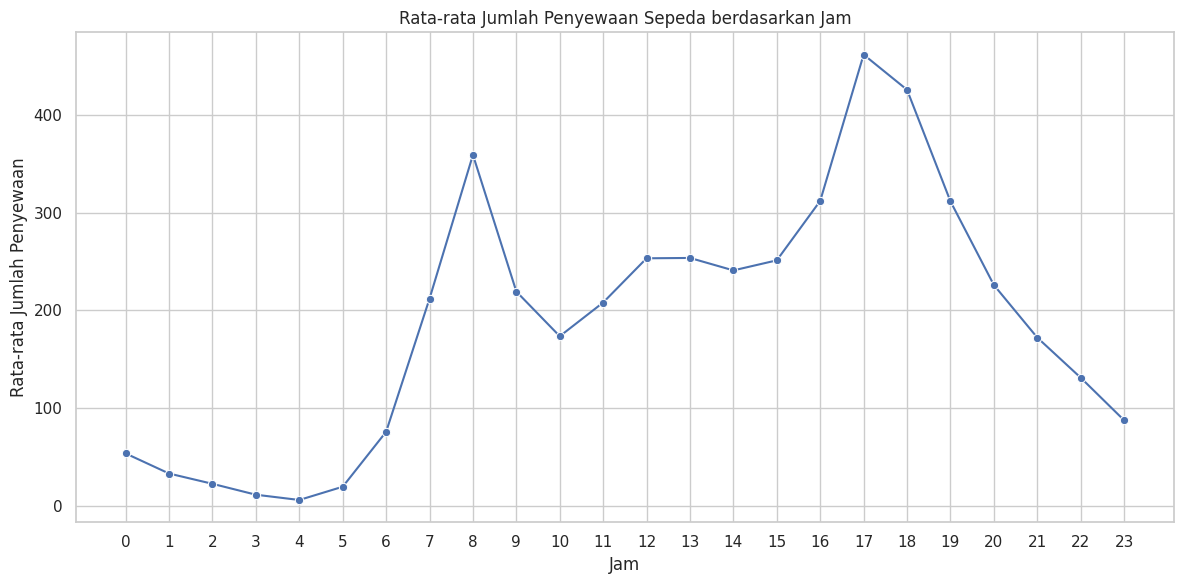

In [46]:
plt.figure(figsize=(12, 6))

sns.lineplot(data=rata_jam, x='hr', y='cnt', marker='o')

plt.title('Rata-rata Jumlah Penyewaan Sepeda berdasarkan Jam')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Pada periode 2011–2012, bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kategori kondisi cuaca, dan kategori cuaca apa yang memiliki rata-rata penyewaan tertinggi dan terendah sebagai dasar penyesuaian operasional layanan?

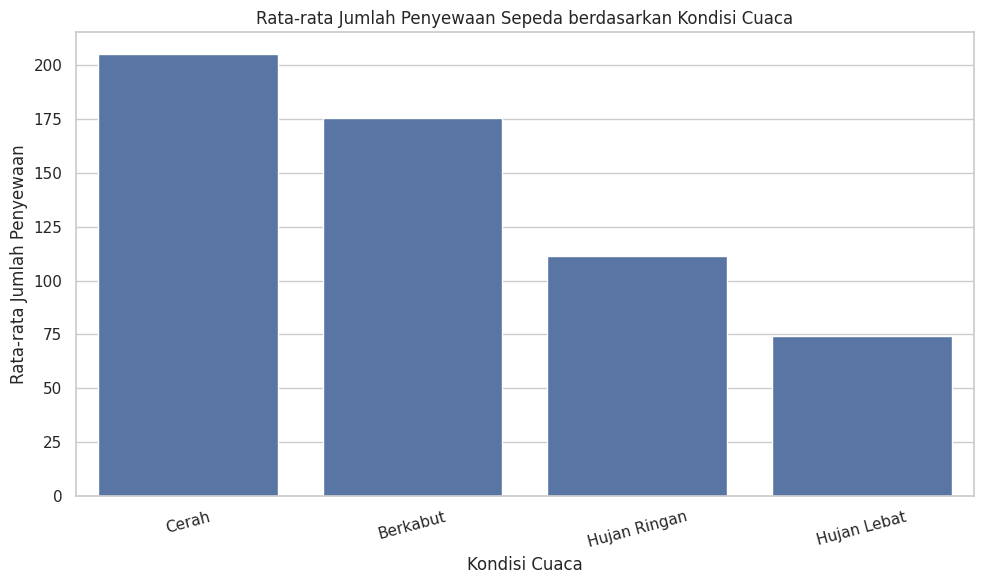

In [47]:
rata_cuaca = (
    df.groupby('weathersit')['cnt']
    .mean()
    .reset_index()
)

rata_cuaca.columns = ['Kondisi Cuaca', 'Rata-rata Penyewaan']

nama_cuaca = {
    1: 'Cerah',
    2: 'Berkabut',
    3: 'Hujan Ringan',
    4: 'Hujan Lebat'
}

rata_cuaca['Nama Cuaca'] = rata_cuaca['Kondisi Cuaca'].map(nama_cuaca)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rata_cuaca,
    x='Nama Cuaca',
    y='Rata-rata Penyewaan'
  )

plt.title('Rata-rata Jumlah Penyewaan Sepeda berdasarkan Kondisi Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Berdasarkan grafik, rata-rata jumlah penyewaan sepeda mengalami perubahan sepanjang hari. Penyewaan mulai meningkat pada pagi hari dan mencapai puncak pertama pada pukul 08.00. Setelah mengalami penurunan, jumlah penyewaan kembali meningkat pada sore hari dan mencapai titik tertinggi pada pukul 17.00 dengan rata-rata 461,45 sepeda. Sementara itu, rata-rata penyewaan terendah terjadi pada pukul 04.00, yaitu sebesar 6,35 sepeda. Hasil ini menunjukkan bahwa aktivitas penyewaan cenderung lebih tinggi pada pagi dan sore hari, terutama pada pukul 17.00. Informasi tersebut dapat menjadi pertimbangan dalam menentukan waktu prioritas ketersediaan sepeda.

- Berdasarkan hasil visualisasi, rata-rata jumlah penyewaan sepeda tertinggi terdapat pada kondisi cuaca kategori 1 (cerah atau sedikit berawan), yaitu sebesar 204,87 sepeda. Rata-rata penyewaan kemudian menurun pada kategori cuaca 2 dan 3. Sementara itu, kategori cuaca 4 memiliki rata-rata penyewaan terendah, yaitu sebesar 74,33 sepeda. Namun, kategori cuaca 4 hanya memiliki 3 pengamatan, sehingga hasilnya perlu ditafsirkan secara hati-hati. Perbedaan rata-rata penyewaan berdasarkan kondisi cuaca dapat menjadi gambaran awal dalam mempertimbangkan penyesuaian operasional layanan.

## Analisis Lanjutan (Opsional)

Pada tahap ini dilakukan analisis lanjutan menggunakan teknik Manual Grouping dan Binning.

1. **Manual Grouping** digunakan untuk mengelompokkan waktu penyewaan sepeda menjadi empat kategori, yaitu pagi, siang, sore, dan malam. Pengelompokan ini bertujuan untuk mengetahui periode waktu dengan rata-rata penyewaan tertinggi.

2. **Binning** digunakan untuk mengelompokkan suhu berdasarkan nilai pada kolom `temp` ke dalam kategori dingin, sedang, dan panas. Teknik ini bertujuan untuk melihat perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kelompok suhu.

Kedua teknik tersebut diharapkan dapat memberikan gambaran tambahan mengenai pola penyewaan sepeda.

In [48]:
# Mengelompokkan jam ke dalam kategori waktu
def kategori_waktu(jam):
    if 6 <= jam <= 10:
        return 'Pagi'
    elif 11 <= jam <= 15:
        return 'Siang'
    elif 16 <= jam <= 20:
        return 'Sore'
    else:
        return 'Malam'

df['kategori_waktu'] = df['hr'].apply(kategori_waktu)

# Menghitung rata-rata penyewaan berdasarkan kategori waktu
rata_waktu = (
    df.groupby('kategori_waktu', observed=True)['cnt']
    .mean()
    .reset_index()
    .sort_values('cnt', ascending=False)
)

rata_waktu

,kategori_waktu,cnt
3,Sore,347.343304
2,Siang,241.475563
1,Pagi,208.092210
0,Malam,60.604799


In [49]:
# Mengelompokkan suhu menggunakan teknik binning
df['kategori_suhu'] = pd.cut(
    df['temp'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Dingin', 'Sedang', 'Panas'],
    include_lowest=True
)

# Menghitung rata-rata penyewaan berdasarkan kategori suhu
rata_suhu = (
    df.groupby('kategori_suhu', observed=True)['cnt']
    .mean()
    .reset_index()
)

rata_suhu

,kategori_suhu,cnt
0,Dingin,84.378486
1,Sedang,177.897758
2,Panas,268.663925


**Insight:** (Opsional)
- Berdasarkan hasil Manual Grouping, kategori waktu sore memiliki rata-rata jumlah penyewaan sepeda tertinggi, yaitu 347,34 sepeda. Selanjutnya, kategori siang memiliki rata-rata 241,48 sepeda, pagi sebesar 208,09 sepeda, dan malam sebesar 60,60 sepeda. Hasil ini menunjukkan bahwa aktivitas penyewaan sepeda cenderung lebih tinggi pada sore hari dibandingkan periode waktu lainnya.

- Berdasarkan hasil Binning, kategori suhu panas memiliki rata-rata jumlah penyewaan tertinggi, yaitu 268,66 sepeda. Kategori suhu sedang memiliki rata-rata 177,90 sepeda, sedangkan kategori suhu dingin memiliki rata-rata 84,38 sepeda. Hasil ini menunjukkan adanya kecenderungan peningkatan jumlah penyewaan sepeda pada kategori suhu yang lebih tinggi.

In [50]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis, rata-rata jumlah penyewaan sepeda mengalami perubahan sepanjang hari. Rata-rata penyewaan tertinggi terjadi pada pukul 17.00, yaitu sebesar 461,45 sepeda, sedangkan rata-rata terendah terjadi pada pukul 04.00 sebesar 6,35 sepeda. Aktivitas penyewaan juga menunjukkan peningkatan pada pagi hari, khususnya pukul 08.00. Hasil pengelompokan waktu memperlihatkan bahwa periode sore menjadi waktu dengan rata-rata penyewaan tertinggi, yaitu sebesar 347,34 sepeda.
- **Conclusion pertanyaan 2:** Berdasarkan hasil analisis, terdapat perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca. Kondisi cuaca kategori 1 (cerah atau sedikit berawan) memiliki rata-rata penyewaan tertinggi sebesar 204,87 sepeda, sedangkan kategori 4 (hujan lebat atau salju lebat) memiliki rata-rata terendah sebesar 74,33 sepeda. Selain itu, hasil pengelompokan suhu menunjukkan bahwa kategori suhu panas memiliki rata-rata penyewaan lebih tinggi dibandingkan kategori suhu sedang dan dingin. Namun, hasil pada kategori cuaca 4 perlu ditafsirkan secara hati-hati karena hanya memiliki 3 pengamatan.

**Rekomendasi Action Item:**

Berdasarkan hasil analisis, terdapat beberapa rekomendasi yang dapat diterapkan oleh pengelola layanan penyewaan sepeda:

- Mengoptimalkan ketersediaan sepeda pada jam-jam dengan permintaan tinggi, terutama pukul 07.00–09.00 dan 16.00–18.00, agar pengguna lebih mudah memperoleh sepeda.
- Menyesuaikan distribusi sepeda berdasarkan pola permintaan pada setiap periode waktu, khususnya pada sore hari yang memiliki rata-rata penyewaan tertinggi.
- Mempertimbangkan kondisi cuaca dan suhu dalam perencanaan operasional serta memberikan informasi kepada pengguna mengenai kondisi cuaca sebelum melakukan penyewaan.

In [51]:
# Menyimpan data yang telah dibersihkan untuk dashboard
df.to_csv('main_data.csv', index=False)

print("File main_data.csv berhasil disimpan.")

File main_data.csv berhasil disimpan.


In [52]:
from google.colab import files
files.download('main_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>